# 02. 파이프라인 전체 실행 — 데이터 적재부터 제출 파일까지

이 노트북은 `make data && make train` 이 하는 일을 순서대로 보여 준다. 결과는 `scripts/train.py` 와 같다(같은 함수, 같은 시드).

1. 원본 데이터 적재
2. 전처리·결합 (`build_dataset`)
3. 결측 전략 비교와 모델 학습 (검증 2025)
4. 롤링 검증 (2022·2023)
5. 최종 학습과 2026 평가 조합 예측 → 제출 파일
6. 시각화
7. SHAP 해석 (피처가 예측을 어느 방향으로 움직이는지)

실행 시간은 약 2분이다. 저장소 루트에서 `pip install -e .` 를 먼저 해야 한다.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_ai.bloom import build_dataset, load_config
from data_ai.config import PROJECT_ROOT, RAW_DIR, REPORTS_DIR, FIGURES_DIR
from data_ai.evaluate import bloom_metrics
from data_ai.features import STRATEGIES, apply_missing_strategy, feature_columns, to_matrix
from data_ai.models import fit_lgb, predict_cells, importance
from data_ai.utils import set_seed

set_seed()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
print("프로젝트:", PROJECT_ROOT)

프로젝트: /tmp/claude-0/-home-user-data-AI/ef359885-7aad-540d-8f64-1628a1edd882/scratchpad/repro


## 1. 원본 데이터 적재

대회 배포 번들 8개 파일과 팀이 수집한 WAMIS 수위 파일. 열 이름과 기간만 확인한다.

In [2]:
files = ["algae_measure.csv", "asos_daily.csv", "dam_daily.csv", "stations.csv", "eval_pairs.csv", "sample_submission.csv"]
for f in files:
    df_ = pd.read_csv(RAW_DIR / f)
    print(f"{f:24s} {len(df_):>7,}행 × {df_.shape[1]:>2}열   예: {list(df_.columns[:5])}")
wamis = pd.read_csv(PROJECT_ROOT / "data/external/wamis_daily.csv")
print(f"{'wamis_daily.csv':24s} {len(wamis):>7,}행 × {wamis.shape[1]:>2}열   기간 {wamis.date.min()} ~ {wamis.date.max()}")
pd.read_csv(RAW_DIR / "algae_measure.csv").head(3)

algae_measure.csv          2,939행 × 25열   예: ['station_id', 'station_name', 'rowno', 'swmn_code', 'river_lkmh_se']
asos_daily.csv            32,208행 × 18열   예: ['stnId', 'stnNm', 'tm', 'avgTa', 'maxTa']


dam_daily.csv             79,964행 × 12열   예: ['obs_date', 'dam_code', 'dam_name', 'suge', 'rwl']
stations.csv                   5행 × 12열   예: ['station_id', 'station_name', 'swmn_code', 'swmn_nm', 'river_lake']
eval_pairs.csv             2,754행 ×  6열   예: ['station_id', 'station_name', 'base_date', 'target_date', 'lag_days']
sample_submission.csv        124행 ×  4열   예: ['station_id', 'base_date', 'target_date', 'pred_cells']
wamis_daily.csv           28,041행 ×  7열   기간 2016-01-01 ~ 2026-10-23


,station_id,station_name,rowno,swmn_code,river_lkmh_se,swmn_nm,swmn_detail_nm,detail_adres,chck_de,iem_wtrtp,iem_ph,iem_doc,iem_trp,iem_tur,iem_chla,iem_bgalage_cell_co,iem_bgalage_microsts,iem_bgalage_anba,iem_bgalage_osrtria,iem_bgalage_apzo,iem_geosm,iem_mib2,iem_microstlr,dominant_genus,over_caution
0,CS,칠서,NaN,2020G33,하천,낙동강,칠서,상류 4km창녕함안보 상류 12km,2016-01-04,NaN,NaN,NaN,NaN,NaN,NaN,241.000,0.000,52.000,0.000,189.000,NaN,NaN,NaN,Aphanizomenon,0.000
1,CS,칠서,NaN,2020G33,하천,낙동강,칠서,상류 4km창녕함안보 상류 12km,2016-01-11,NaN,NaN,NaN,NaN,NaN,NaN,215.000,0.000,0.000,0.000,215.000,NaN,NaN,NaN,Aphanizomenon,0.000
2,CS,칠서,NaN,2020G33,하천,낙동강,칠서,상류 4km창녕함안보 상류 12km,2016-01-18,NaN,NaN,NaN,NaN,NaN,NaN,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,0.000


## 2. 전처리·결합

`configs/bloom.yaml` 의 규칙대로 (지점, 측정일) 한 행에 기상·댐·하천·상류 지점 피처와 정답을 붙인다. 모든 집계는 기준일 포함 과거 자료만 쓴다.

In [3]:
cfg = load_config(PROJECT_ROOT / "configs/bloom.yaml")
df = build_dataset(cfg)
df["date"] = pd.to_datetime(df["date"])
print(df.shape)
print(df["split"].value_counts().to_dict())
df[["station_id", "date", "cyano_cells", "water_temp", "w_temp_mean_mean7d", "d_outflow_mean7d", "r_stage", "cells_upstream", "target_cells", "split"]].sample(5, random_state=1)

2026-11-03 00:19:24,142 | INFO | data_ai.bloom | 지점: ['HP', 'GJGR', 'CS', 'MGMR', 'DCHN']


2026-11-03 00:19:24,206 | INFO | data_ai.bloom | 조류경보제: 2939행 → 지점·날짜 정리 후 2939행


2026-11-03 00:19:24,911 | INFO | data_ai.bloom | 기상 결합: 결측 0.2%


2026-11-03 00:19:25,959 | INFO | data_ai.bloom | 댐 결합: 결측 0.0%


2026-11-03 00:19:26,075 | INFO | data_ai.bloom | 하천 결합: 4열, 결측 31.1% (매핑 지점 외 포함)


/tmp/claude-0/-home-user-data-AI/ef359885-7aad-540d-8f64-1628a1edd882/scratchpad/repro/src/data_ai/bloom.py:319: RuntimeWarning: Mean of empty slice
  d.loc[m, "cells_basin_mean"] = np.nanmean(stack, axis=0)[m]
/tmp/claude-0/-home-user-data-AI/ef359885-7aad-540d-8f64-1628a1edd882/scratchpad/repro/src/data_ai/bloom.py:319: RuntimeWarning: Mean of empty slice
  d.loc[m, "cells_basin_mean"] = np.nanmean(stack, axis=0)[m]
/tmp/claude-0/-home-user-data-AI/ef359885-7aad-540d-8f64-1628a1edd882/scratchpad/repro/src/data_ai/bloom.py:319: RuntimeWarning: Mean of empty slice
  d.loc[m, "cells_basin_mean"] = np.nanmean(stack, axis=0)[m]
/tmp/claude-0/-home-user-data-AI/ef359885-7aad-540d-8f64-1628a1edd882/scratchpad/repro/src/data_ai/bloom.py:319: RuntimeWarning: Mean of empty slice
  d.loc[m, "cells_basin_mean"] = np.nanmean(stack, axis=0)[m]
2026-11-03 00:19:26,104 | INFO | data_ai.bloom | 상류 지점 결합: cells_upstream 결측 47.5%, cells_basin_mean 결측 27.1%


2026-11-03 00:19:26,122 | INFO | data_ai.bloom | 정답: eval_pairs 사용 (2754쌍)


2026-11-03 00:19:26,136 | INFO | data_ai.bloom | 최종: 2939행 × 134열, 2012-04-02 ~ 2026-09-10, 분할 {'train': 2310, 'valid': 256, 'none': 185, 'test': 124, 'excluded': 64}, 정답 유효 2566


(2939, 134)
{'train': 2310, 'valid': 256, 'none': 185, 'test': 124, 'excluded': 64}


,station_id,date,cyano_cells,water_temp,w_temp_mean_mean7d,d_outflow_mean7d,r_stage,cells_upstream,target_cells,split
1268,DCHN,2024-06-03,671.000,14.800,20.443,287.556,NaN,NaN,57.000,train
2720,MGMR,2022-11-21,"1,037.000",14.200,14.014,67.912,1.478,3.063,"3,447.000",train
2711,MGMR,2022-10-04,"1,343.000",23.500,22.829,82.642,1.618,3.448,"5,815.000",train
2028,HP,2016-05-30,287.000,24.300,21.971,41.800,25.615,NaN,"1,287.000",train
351,CS,2022-01-17,0.000,3.400,-1.686,66.857,4.960,NaN,0.000,train


## 3. 결측 전략 비교와 학습 (검증 2025)

학습 ≤2024, 검증 2025. 세 전략을 같은 조건으로 비교하고 검증 rmse_log10 이 가장 낮은 것을 고른다. 입력 열은 허용 목록(`feature_columns`)으로만 고르므로 정답·날짜 열은 들어갈 수 없다.

In [4]:
labeled = df["target_valid"]
train_mask, valid_mask = labeled & df["split"].eq("train"), labeled & df["split"].eq("valid")

def run_split(strategy, tr, va, num_rounds=None):
    d = apply_missing_strategy(df, strategy, tr)
    cols = feature_columns(d)
    x_tr, cats = to_matrix(d[tr], cols)
    x_va, _ = to_matrix(d[va], cols, cats)
    y_tr, y_va = d.loc[tr, "log10_target_cells"].to_numpy(), d.loc[va, "log10_target_cells"].to_numpy()
    if num_rounds is None:  # early stopping
        m = fit_lgb(x_tr, y_tr, x_va, y_va)
    else:
        m = fit_lgb(x_tr, y_tr, num_rounds=num_rounds)
    pred = predict_cells(m, x_va)
    return m, pred, bloom_metrics(d.loc[va, "target_cells"], pred), cols

results = {}
for s in STRATEGIES:
    m, pred, met, cols = run_split(s, train_mask, valid_mask)
    results[s] = {**met, "best_iter": m.best_iteration}
pd.DataFrame(results).T[["rmse_log10", "mae_log10", "r2", "nse", "f1_over_threshold", "best_iter"]]

,rmse_log10,mae_log10,r2,nse,f1_over_threshold,best_iter
native,0.714,0.536,0.146,0.146,0.617,400.000
ffill_flag,0.704,0.527,0.173,0.173,0.651,146.000
site_month_median,0.716,0.548,0.168,0.168,0.651,120.000


In [5]:
strategy = min(results, key=lambda k: results[k]["rmse_log10"])
best_iter = max(int(results[strategy]["best_iter"]), 50)
print("선택 전략:", strategy, "| 반복 수:", best_iter, "| 피처 수:", len(cols))

선택 전략: ffill_flag | 반복 수: 146 | 피처 수: 132


## 4. 롤링 검증

해당 연도 이전 자료만 학습해 그 해를 예측한다. 한 해 결과가 우연인지 확인하는 용도.

In [6]:
rows = []
for y in (2022, 2023, 2025):
    tr, va = labeled & (df["year"] < y), labeled & (df["year"] == y)
    _, pred, met, _ = run_split(strategy, tr, va, num_rounds=best_iter)
    rows.append({"검증 연도": y, "n": int(va.sum()), **met})
pd.DataFrame(rows).set_index("검증 연도")[["n", "rmse_log10", "mae_log10", "r2", "nse", "f1_over_threshold"]]

,n,rmse_log10,mae_log10,r2,nse,f1_over_threshold
검증 연도,,,,,,
2022,271,0.832,0.631,0.014,0.014,0.429
2023,248,0.763,0.574,0.027,0.027,0.375
2025,256,0.704,0.527,0.173,0.173,0.651


## 5. 최종 학습과 제출 파일

학습+검증(≤2025) 전체로 다시 학습한 뒤 2026년 평가 조합 124건을 예측한다. 결과를 저장소의 `reports/submission.csv` 와 비교한다.

In [7]:
final_mask = labeled & df["split"].isin(["train", "valid"])
d = apply_missing_strategy(df, strategy, final_mask)
cols = feature_columns(d)
x_all, cats = to_matrix(d[final_mask], cols)
model = fit_lgb(x_all, d.loc[final_mask, "log10_target_cells"].to_numpy(), num_rounds=int(best_iter * 1.1))

test = d[d["is_test"]]
x_te, _ = to_matrix(test, cols, cats)
pred_df = test[["station_id", "date"]].assign(pred_cells=np.rint(predict_cells(model, x_te)).astype(int)).rename(columns={"date": "base_date"})
sub = pd.read_csv(RAW_DIR / "sample_submission.csv", parse_dates=["base_date", "target_date"])
out = sub.drop(columns="pred_cells").merge(pred_df, on=["station_id", "base_date"], how="left")
assert out["pred_cells"].notna().all()

saved = pd.read_csv(REPORTS_DIR / "submission.csv")
n_diff = int((saved["pred_cells"].to_numpy() != out["pred_cells"].to_numpy()).sum())
print(f"평가 조합 {len(out)}건 예측 완료. 저장소 submission.csv 와 불일치 {n_diff}건")
out.head(10)

평가 조합 124건 예측 완료. 저장소 submission.csv 와 불일치 0건


,station_id,base_date,target_date,pred_cells
0,HP,2026-05-04,2026-05-11,21
1,HP,2026-05-11,2026-05-18,49
2,HP,2026-05-18,2026-05-26,67
3,HP,2026-05-26,2026-06-01,117
4,HP,2026-06-01,2026-06-08,1852
5,HP,2026-06-08,2026-06-15,2276
6,HP,2026-06-15,2026-06-22,4439
7,HP,2026-06-22,2026-06-29,4239
8,HP,2026-06-29,2026-07-06,3913
9,HP,2026-07-06,2026-07-13,2000


## 6. 시각화

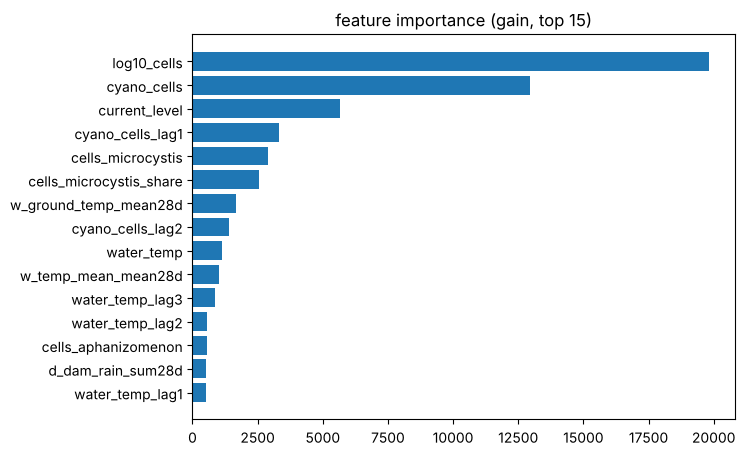

In [8]:
fi = importance(model).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(fi["feature"], fi["gain"]); ax.set_title("feature importance (gain, top 15)"); plt.show()

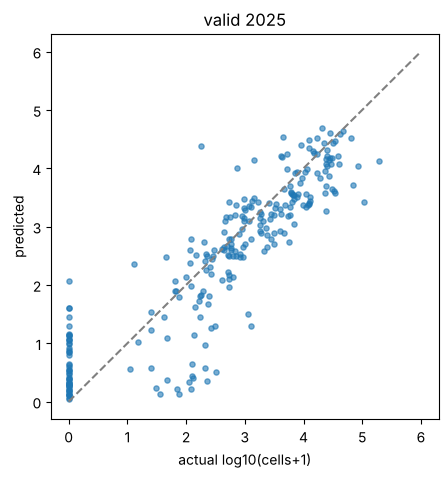

In [9]:
_, pred_v, _, _ = run_split(strategy, train_mask, valid_mask, num_rounds=best_iter)
truth_v = df.loc[valid_mask, "target_cells"].to_numpy()
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(np.log10(truth_v + 1), np.log10(pred_v + 1), s=14, alpha=0.6)
ax.plot([0, 6], [0, 6], "--", color="gray"); ax.set_xlabel("actual log10(cells+1)"); ax.set_ylabel("predicted"); ax.set_title("valid 2025"); plt.show()

In [10]:
from IPython.display import Image, display
for name in ["fig_valid2025_timeseries.png", "fig_submission_2026.png"]:
    p = FIGURES_DIR / name
    if p.exists():
        display(Image(filename=str(p), width=800))

## 7. SHAP 해석

최종 모델에 대해 검증 2025 행의 SHAP 값을 계산한다. 막대 그림은 전체 기여도 크기, 점 그림은 값이 클 때(빨강) 예측을 올리는지 내리는지 보여 준다. SHAP 값은 log10(세포수+1) 단위다.

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP 행렬: (256, 132) | 기준값(log10): 2.131


/tmp/ipykernel_819/2501881795.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, x_v, plot_type="bar", max_display=15, show=False)


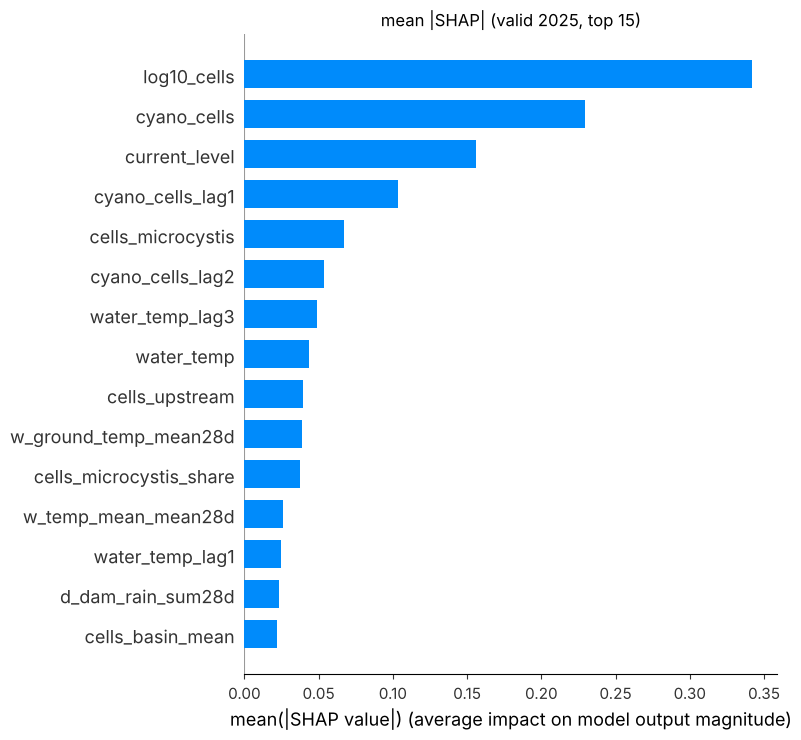

/tmp/ipykernel_819/2501881795.py:10: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, x_v, max_display=15, show=False)


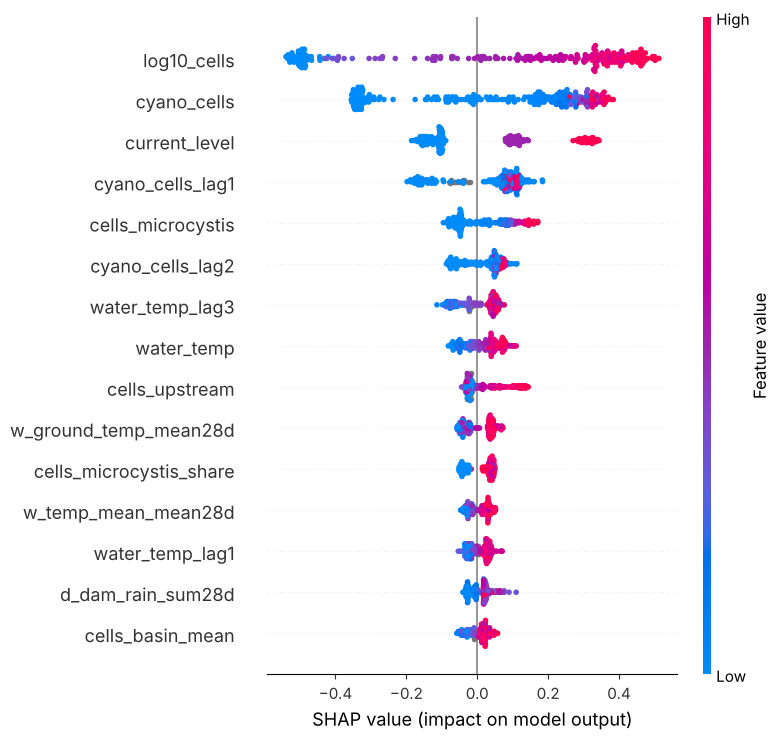

In [11]:
import shap

x_v, _ = to_matrix(d[valid_mask], cols, cats)
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(x_v)
print("SHAP 행렬:", sv.shape, "| 기준값(log10):", round(float(explainer.expected_value), 3))

shap.summary_plot(sv, x_v, plot_type="bar", max_display=15, show=False)
plt.title("mean |SHAP| (valid 2025, top 15)"); plt.tight_layout(); plt.show()
shap.summary_plot(sv, x_v, max_display=15, show=False)
plt.tight_layout(); plt.show()

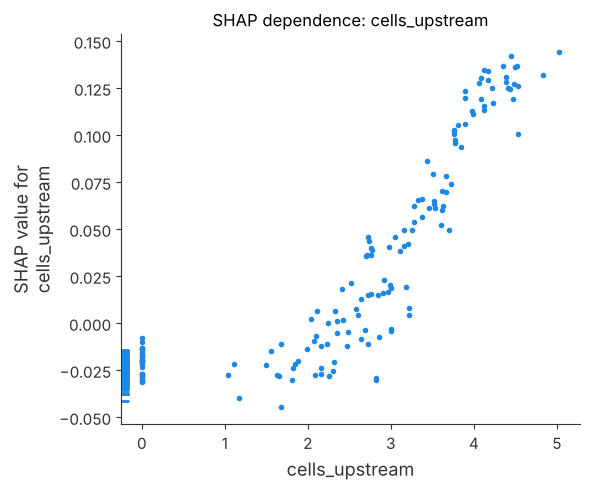

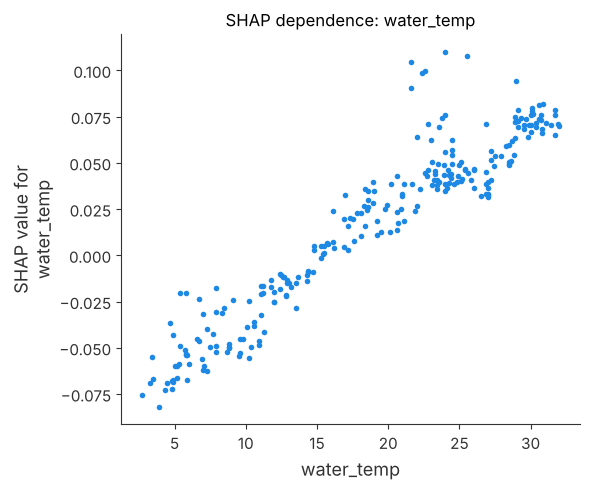

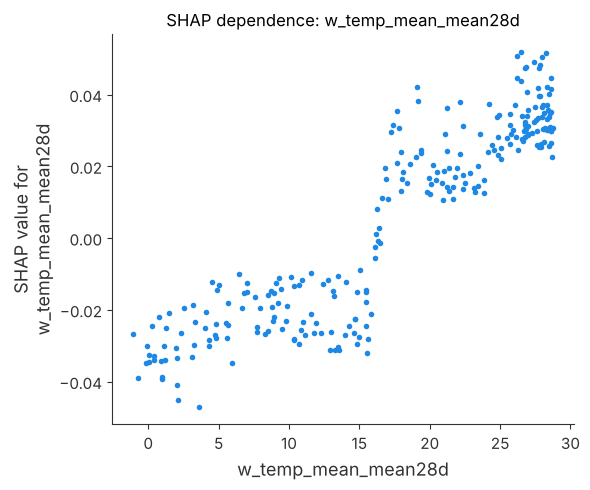

In [12]:
# 상류 지점·수계 평균 세포수(4차 실험에서 채택)와 수온의 방향 확인: 의존도 그림
for feat in ["cells_upstream", "water_temp", "w_temp_mean_mean28d"]:
    if feat in x_v.columns:
        shap.dependence_plot(feat, sv, x_v, interaction_index=None, show=False)
        plt.title(f"SHAP dependence: {feat}"); plt.tight_layout(); plt.show()

## 정리

- 제출 모델: LightGBM(log10 목표, extra_trees) + 상류 지점 세포수 입력, 결측 전략은 검증에서 자동 선택
- 검증 2025 rmse_log10 ≈ 0.70 (persistence 0.88), 원 단위 R² ≈ 0.17 (목표 0.6 미달)
- SHAP: 기준일 세포수(log10_cells, cyano_cells)가 압도적이고, 수온·기온 28일 평균은 높을수록 예측을 올림. 상류 지점 세포수는 양의 방향
- 실험 전체 기록은 `docs/modeling_notes.md`, 방법 설명은 `docs/method_description.md`